# Naming patterns: exploratory analysis

The analysis follows the three research questions: **time and spelling**, **place**, and **recorded-sex associations**. Run after `01_state_preparation.ipynb`. National and state observations remain separate.

All denominators use **published SSA counts**, not all births. Missing national name–sex counts are bounded between 0 and 4 when analysing suppression. These bounds address publication limits, not unrecorded applications or early historical undercoverage. Results are descriptive, and names, years and states are dependent observations.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif (ROOT / 'group_project_dsfm').is_dir():
    ROOT = ROOT / 'group_project_dsfm'
FIGURES, TABLES = ROOT / 'reports/figures', ROOT / 'reports/tables'
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

# Preserve literal spellings; state and national rows remain separate.
st = pd.read_csv(ROOT / 'data/processed/state_names.csv.gz',
    usecols=['state', 'sex', 'year', 'name', 'count', 'rank'],
    dtype={'state': 'category', 'sex': 'category', 'year': 'int16',
           'name': 'string', 'count': 'int64', 'rank': 'int32'},
    keep_default_na=False)
nat = pd.read_csv(ROOT / 'data/processed/national_names.csv.gz',
    usecols=['year', 'sex', 'name', 'count', 'published_share'],
    dtype={'sex': 'category', 'year': 'int16', 'name': 'string', 'count': 'int64'},
    keep_default_na=False)
national_totals = nat.groupby(['sex', 'year'], observed=True)['count'].sum()
NUM = {}
PLACEHOLDERS = {'baby', 'babyboy', 'babygirl', 'unknown', 'unnamed', 'infant'}
COLORS = {'F': '#2f5f8a', 'M': '#c0602b'}
INK, MUTED, GRID = '#222222', '#666666', '#e6e6e6'
plt.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 180, 'font.family': 'DejaVu Sans',
    'font.size': 10.5, 'text.color': INK, 'axes.labelcolor': MUTED,
    'axes.titlesize': 11, 'axes.titlelocation': 'left',
    'axes.edgecolor': GRID, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'grid.color': GRID,
    'axes.axisbelow': True, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white'
})

# Shared figure formatting keeps the seven report figures consistent.
def header(fig, title, subtitle, x=.07):
    fig.text(x, .975, title, fontsize=13.5, color=INK, va='top')
    fig.text(x, .925, subtitle, fontsize=10, color=MUTED, va='top')

def footer(fig, text, x=.07):
    fig.text(x, .012, text, fontsize=8.5, color=MUTED, va='bottom')

def save(fig, name):
    fig.savefig(FIGURES / name, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def pct(ax, axis='y'):
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(PercentFormatter(1, decimals=0))

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}')
print(f'{len(st):,} state records; {len(nat):,} national records.')


Python 3.12.0 | pandas 2.3.3 | NumPy 2.5.4
6,696,687 state records; 2,181,032 national records.


## Context: concentration of published names

Top-ten concentration is the combined count of the ten highest-ranked names divided by the published total in each state–sex–year group. The median and interquartile band give equal weight to all 50 states and DC. Ranks break count ties alphabetically. This measure describes concentration within the published distribution; suppression particularly affects smaller states.

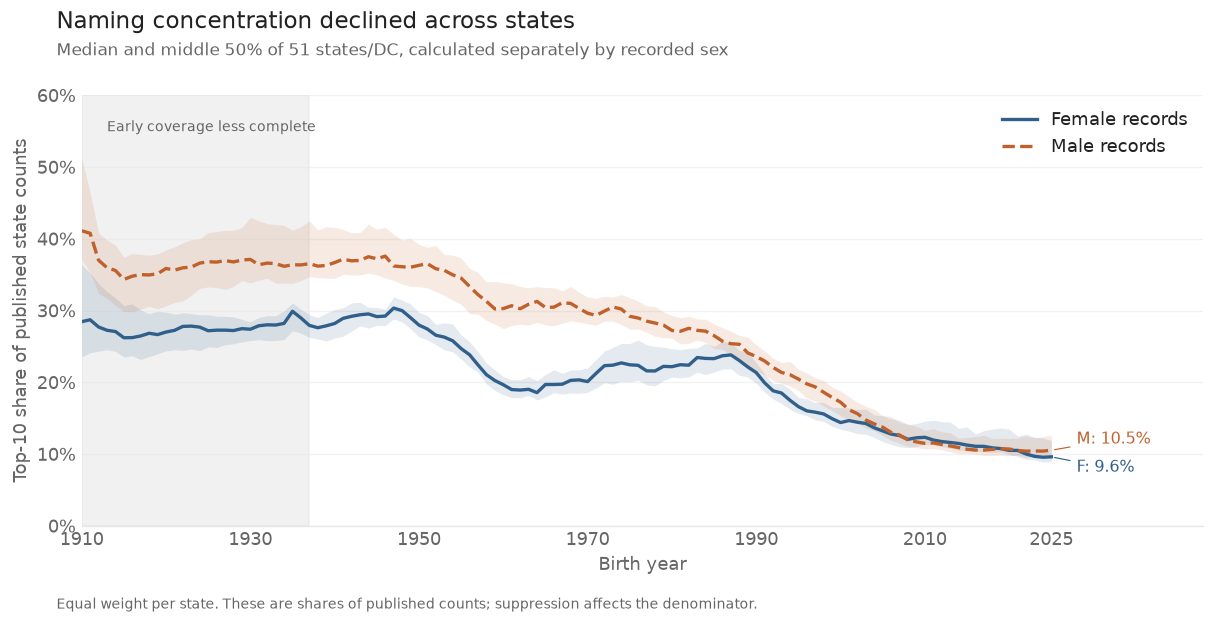

sex,F,M
year,,
1950,0.2798,0.3631
1980,0.2219,0.2723
2025,0.0962,0.1054


In [2]:
GROUP = ['state', 'sex', 'year']
gs = st.groupby(GROUP, observed=True)['count'].sum().to_frame('published_count')
gs['top10_share'] = (st.loc[st['rank'].le(10)].groupby(GROUP, observed=True)['count'].sum()
                     / gs['published_count'])
trend = gs.groupby(['year', 'sex'], observed=True)['top10_share'].agg(
    median='median', q25=lambda v: v.quantile(.25), q75=lambda v: v.quantile(.75))
med = trend['median'].unstack('sex')
trend.reset_index().to_csv(TABLES / 'concentration_by_year.csv', index=False)
NUM['concentration'] = {str(year): {sex: float(med.loc[year, sex]) for sex in ['F', 'M']}
                        for year in [1950, 1980, 2025]}

fig, ax = plt.subplots(figsize=(10.5, 5.2))
for sex, label in [('F', 'Female records'), ('M', 'Male records')]:
    v = trend.xs(sex, level='sex')
    ax.fill_between(v.index, v['q25'], v['q75'], color=COLORS[sex], alpha=.13, lw=0)
    ax.plot(v.index, v['median'], color=COLORS[sex], lw=2,
            ls='-' if sex == 'F' else '--', label=label)
    endpoint = float(v.loc[2025, 'median'])
    ax.annotate(f'{sex}: {endpoint:.1%}', (2025, endpoint),
                xytext=(2028, endpoint + (.015 if sex == 'M' else -.015)),
                color=COLORS[sex], fontsize=9.5, va='center',
                arrowprops={'arrowstyle': '-', 'color': COLORS[sex], 'lw': .7})
ax.axvspan(1910, 1937, color=GRID, alpha=.55, zorder=0)
ax.text(1913, .55, 'Early coverage less complete', color=MUTED, fontsize=8.5)
ax.set(xlabel='Birth year', ylabel='Top-10 share of published state counts',
       xlim=(1910, 2043), ylim=(0, .60))
ax.set_xticks([1910, 1930, 1950, 1970, 1990, 2010, 2025])
pct(ax)
ax.grid(axis='y', lw=.8)
ax.legend(frameon=False, loc='upper right')
header(fig, 'Naming concentration declined across states',
       'Median and middle 50% of 51 states/DC, calculated separately by recorded sex')
footer(fig, 'Equal weight per state. These are shares of published counts; suppression affects the denominator.')
fig.subplots_adjust(left=.09, right=.98, top=.84, bottom=.15)
save(fig, 'fig1_concentration.png')
display(med.loc[[1950, 1980, 2025]].round(4))


## RQ1: popularity profiles over time

Select national name–sex series with an observed peak share of at least **0.1% of published counts**, peaking during **1900–2005**. A missing name–sex–year has a count between 0 and 4 under the publication threshold; divide those bounds by the published sex–year total and the observed peak share. The selected peak is sufficiently large that the missing-count bound cannot exceed it (see the numerical summary).

Panel A compares median lower/upper profiles within a common **±20-year window**, fully observed for every selected series. Panel B counts **all years at or above half the observed peak in 1880–2025**, grouped by peak decade. These are not contiguous durations or complete lifetimes: the observation boundaries can truncate trajectories, and the 2000s peak group ends in 2005.

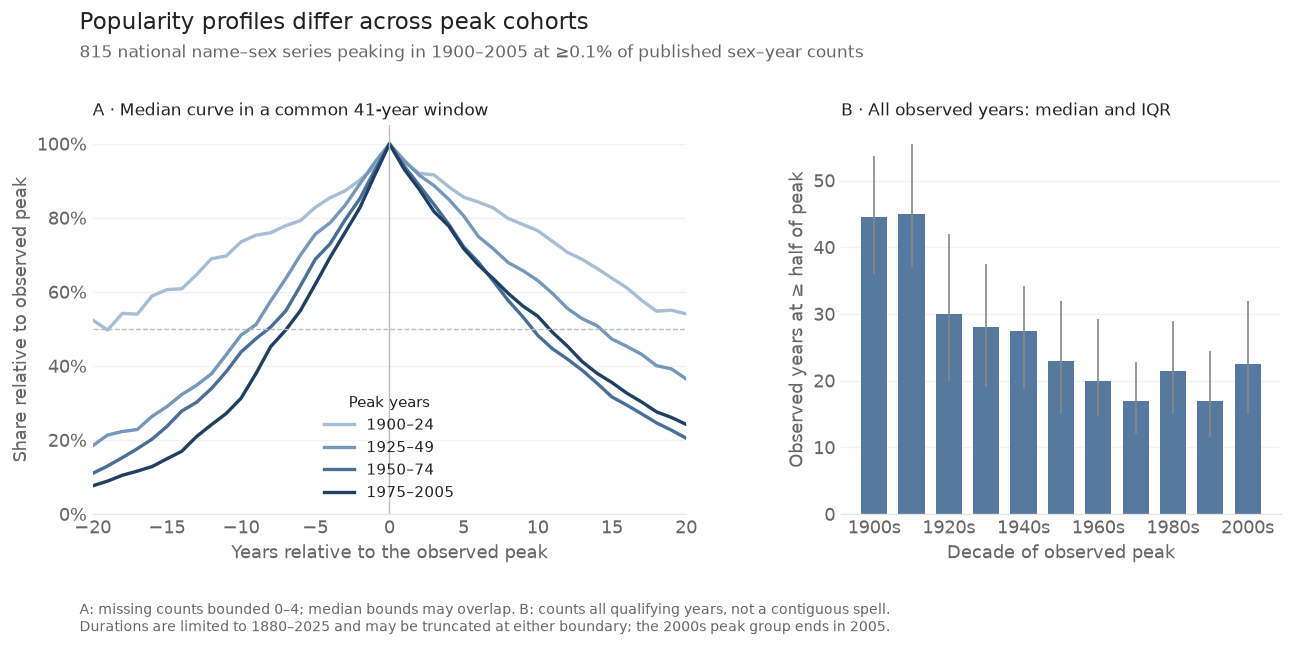

,names,median_lower,median_upper,q25,q75
peak_decade,,,,,
1900,48,44.5,44.5,36.00,53.75
1910,63,45.0,45.0,37.00,55.50
1920,36,30.0,30.0,20.00,42.00
1930,64,28.0,28.0,19.00,37.50
1940,52,27.5,27.5,18.75,34.25
1950,71,23.0,23.0,15.00,32.00
1960,96,20.0,20.0,14.75,29.25
1970,94,17.0,17.0,12.00,22.75
1980,100,21.5,21.5,15.00,29.00


In [3]:
PEAK_MIN = .001
idx = nat.groupby(['name', 'sex'], observed=True)['published_share'].idxmax()
peaks = nat.loc[idx, ['name', 'sex', 'year', 'published_share']].rename(
    columns={'year': 'peak_year', 'published_share': 'peak_share'})
peaks = peaks.loc[peaks['peak_share'].ge(PEAK_MIN) & peaks['peak_year'].between(1900, 2005)].copy()

# Use all observed years for duration; the curve uses a common +/-20-year window.
years = np.arange(1880, 2026)
full = peaks.loc[peaks.index.repeat(len(years))].copy()
full['year'] = np.tile(years, len(peaks))
full = full.merge(nat[['name', 'sex', 'year', 'count']], on=['name', 'sex', 'year'], how='left')
full = full.join(national_totals.rename('published_total'), on=['sex', 'year'])
hidden = full['count'].isna()
full['count_lower'] = full['count'].fillna(0)
full['count_upper'] = full['count'].fillna(4)
full['relative_lower'] = full['count_lower'] / full['published_total'] / full['peak_share']
full['relative_upper'] = full['count_upper'] / full['published_total'] / full['peak_share']
full['offset'] = full['year'] - full['peak_year']
full['near_lower'] = full['relative_lower'].ge(.5)
full['near_upper'] = full['relative_upper'].ge(.5)
half = full.groupby(['name', 'sex'], observed=True).agg(
    peak_year=('peak_year', 'first'), peak_share=('peak_share', 'first'),
    years_half_lower=('near_lower', 'sum'), years_half_upper=('near_upper', 'sum'))
half['peak_decade'] = half['peak_year'] // 10 * 10
hd = half.groupby('peak_decade').agg(
    names=('years_half_lower', 'size'), median_lower=('years_half_lower', 'median'),
    median_upper=('years_half_upper', 'median'),
    q25=('years_half_lower', lambda v: v.quantile(.25)),
    q75=('years_half_upper', lambda v: v.quantile(.75)))
ERAS = [(1900, 1924, '1900–24'), (1925, 1949, '1925–49'),
        (1950, 1974, '1950–74'), (1975, 2005, '1975–2005')]
ERA_COLORS = ['#a6bed5', '#7597b9', '#496f97', '#1f3f63']
curves, era_rows = [], []
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5.4), gridspec_kw={'width_ratios': [1.35, 1]})
for (start, end, label), color in zip(ERAS, ERA_COLORS):
    selected = full.loc[full['peak_year'].between(start, end) & full['offset'].between(-20, 20)]
    curve = selected.groupby('offset').agg(
        lower=('relative_lower', 'median'), upper=('relative_upper', 'median'), names=('name', 'size'))
    curve['peak_era'] = label
    curves.append(curve.reset_index())
    a.fill_between(curve.index, curve['lower'], curve['upper'], color=color, alpha=.2)
    a.plot(curve.index, curve['lower'], color=color, lw=2, label=label)
    h = half.loc[half['peak_year'].between(start, end)]
    era_rows.append({'peak_era': label, 'names': len(h),
        'median_years_half_lower': float(h['years_half_lower'].median()),
        'median_years_half_upper': float(h['years_half_upper'].median())})
a.axvline(0, color='#bbb', lw=.8)
a.axhline(.5, color='#bbb', lw=.8, ls='--')
a.set(xlabel='Years relative to the observed peak', ylabel='Share relative to observed peak',
      xlim=(-20, 20), ylim=(0, 1.05))
pct(a)
a.grid(axis='y', lw=.8)
a.legend(title='Peak years', frameon=False, fontsize=9, title_fontsize=9)
a.set_title('A · Median curve in a common 41-year window', fontsize=10)
b.bar(hd.index, hd['median_lower'], width=7, color='#55799f')
b.errorbar(hd.index, hd['median_lower'],
    yerr=[hd['median_lower'] - hd['q25'], hd['q75'] - hd['median_lower']],
    fmt='none', ecolor='#888888', lw=1)
b.set(xlabel='Decade of observed peak', ylabel='Observed years at ≥ half of peak')
b.set_xticks(hd.index[::2], [f'{d}s' for d in hd.index[::2]])
b.grid(axis='y', lw=.8)
b.set_title('B · All observed years: median and IQR', fontsize=10)
header(fig, 'Popularity profiles differ across peak cohorts',
       f'{len(peaks):,} national name–sex series peaking in 1900–2005 at ≥0.1% of published sex–year counts')
footer(fig, 'A: missing counts bounded 0–4; median bounds may overlap. B: counts all qualifying years, not a contiguous spell.' + chr(10) +
       'Durations are limited to 1880–2025 and may be truncated at either boundary; the 2000s peak group ends in 2005.')
fig.subplots_adjust(left=.08, right=.98, top=.80, bottom=.20, wspace=.30)
save(fig, 'fig2_life_cycles.png')

half.reset_index().to_csv(TABLES / 'life_cycle_names.csv', index=False)
hd.reset_index().to_csv(TABLES / 'life_cycle_by_peak_decade.csv', index=False)
pd.concat(curves, ignore_index=True).to_csv(TABLES / 'life_cycle_curves.csv', index=False)
pd.DataFrame(era_rows).to_csv(TABLES / 'life_cycle_by_peak_era.csv', index=False)
NUM['life_cycles'] = {
    'name_sex_series': int(len(peaks)), 'curve_window': [-20, 20],
    'duration_window': [1880, 2025],
    'maximum_hidden_relative_upper': float(full.loc[hidden, 'relative_upper'].max()),
    'durations_affected_by_bounds': int(half['years_half_lower'].ne(half['years_half_upper']).sum()),
    'median_years_by_peak_decade': {str(k): float(v) for k, v in hd['median_lower'].items()},
    'pooled_era_medians': era_rows
}
display(hd)

### RQ1: spelling and cohort

Aggregate national published counts by final letter and recorded sex. The displayed letters are selected illustrations, not an exhaustive ranking. Decade comparisons pool counts over all ten years. A separate table records count-weighted mean birth years for two-letter endings with more than 2 million published counts. These are descriptive associations; prediction on held-out names remains future work.

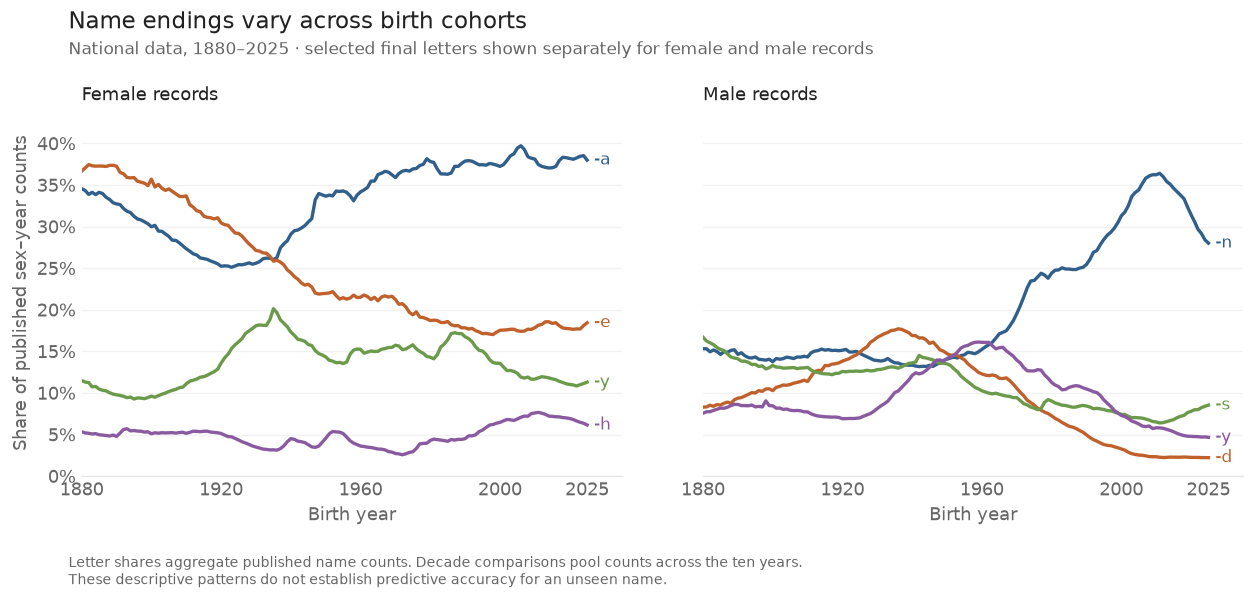

,1940s,2000s
n,0.133973,0.341313
d,0.160539,0.026776
s,0.139131,0.070297
y,0.131387,0.064479


In [4]:
# Aggregate actual published counts; selected letters are illustrative, not a fitted model.
letters = nat.assign(ending=nat['name'].str[-1].str.lower())
letter_counts = letters.groupby(['sex', 'year', 'ending'], observed=True)['count'].sum().rename('count')
letter_shares = letter_counts.to_frame().join(national_totals.rename('published_total'), on=['sex', 'year'])
letter_shares['published_share'] = letter_shares['count'] / letter_shares['published_total']
letter_shares.reset_index().to_csv(TABLES / 'name_endings_by_year.csv', index=False)
ENDS = {'F': ['a', 'e', 'y', 'h'], 'M': ['n', 'd', 's', 'y']}
END_COLORS = ['#2f5f8a', '#c0602b', '#6a9a4a', '#8a5aa0']
ending_numbers = {}
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, sex, title in zip(axes, ['F', 'M'], ['Female records', 'Male records']):
    t = letter_shares.xs(sex)['published_share'].unstack('ending', fill_value=0)
    ending_numbers[sex] = {}
    for ending, color in zip(ENDS[sex], END_COLORS):
        ax.plot(t.index, t[ending], color=color, lw=2)
        ax.text(2027, t.loc[2025, ending], f'-{ending}', color=color, fontsize=10, va='center')
        period_shares = {}
        for decade in [1940, 2000]:
            counts = letter_counts.xs(sex).loc[decade:decade + 9]
            numerator = counts.xs(ending, level='ending').sum()
            denominator = national_totals.xs(sex).loc[decade:decade + 9].sum()
            period_shares[f'{decade}s'] = float(numerator / denominator)
        ending_numbers[sex][ending] = period_shares
    ax.set(title=title, xlim=(1880, 2035), ylim=(0, .44), xlabel='Birth year')
    ax.set_xticks([1880, 1920, 1960, 2000, 2025])
    pct(ax)
    ax.grid(axis='y', lw=.8)
axes[0].set_ylabel('Share of published sex–year counts')
header(fig, 'Name endings vary across birth cohorts',
       'National data, 1880–2025 · selected final letters shown separately for female and male records')
footer(fig, 'Letter shares aggregate published name counts. Decade comparisons pool counts across the ten years.' + chr(10) +
       'These descriptive patterns do not establish predictive accuracy for an unseen name.')
fig.subplots_adjust(left=.08, right=.96, top=.81, bottom=.20, wspace=.15)
save(fig, 'fig3_endings.png')

# Descriptive centroids for common two-letter endings; predictive tests are later work.
end2 = nat.assign(ending=nat['name'].str[-2:].str.lower(), weighted_year=nat['year'] * nat['count'])
end2 = end2.groupby(['sex', 'ending'], observed=True)[['count', 'weighted_year']].sum()
end2['count_weighted_mean_year'] = end2['weighted_year'] / end2['count']
end2 = end2.loc[end2['count'].gt(2_000_000)]
end2.reset_index().to_csv(TABLES / 'two_letter_endings.csv', index=False)
NUM['endings'] = {'decade_method': 'pooled published counts', 'selected_letters': ending_numbers}
display(pd.DataFrame(ending_numbers['M']).T)
del letters

## RQ2: state profiles and conditional divergence

For every fifth year, compare each state’s name distribution with the pooled other states within recorded sex, using Jensen–Shannon divergence (base 2, in bits). Each comparison is restricted and renormalised to names published in both distributions.

The conditional baseline averages **30 multinomial draws** from the published rest-of-states profile, at the focal state’s published count total, with simulated counts below 5 hidden. **Baseline-adjusted divergence** is observed JSD minus that average. A fixed seed makes the simulation reproducible; exported standard errors describe Monte Carlo precision only. The reference itself is suppressed and the shared vocabulary can change across draws, so adjustment is not complete correction for sampling, suppression or historical coverage.

Completed conditional baseline for 1910.
Completed conditional baseline for 1915.
Completed conditional baseline for 1920.
Completed conditional baseline for 1925.
Completed conditional baseline for 1930.
Completed conditional baseline for 1935.
Completed conditional baseline for 1940.
Completed conditional baseline for 1945.
Completed conditional baseline for 1950.
Completed conditional baseline for 1955.
Completed conditional baseline for 1960.
Completed conditional baseline for 1965.
Completed conditional baseline for 1970.
Completed conditional baseline for 1975.
Completed conditional baseline for 1980.
Completed conditional baseline for 1985.
Completed conditional baseline for 1990.
Completed conditional baseline for 1995.
Completed conditional baseline for 2000.
Completed conditional baseline for 2005.
Completed conditional baseline for 2010.
Completed conditional baseline for 2015.
Completed conditional baseline for 2020.
Completed conditional baseline for 2025.


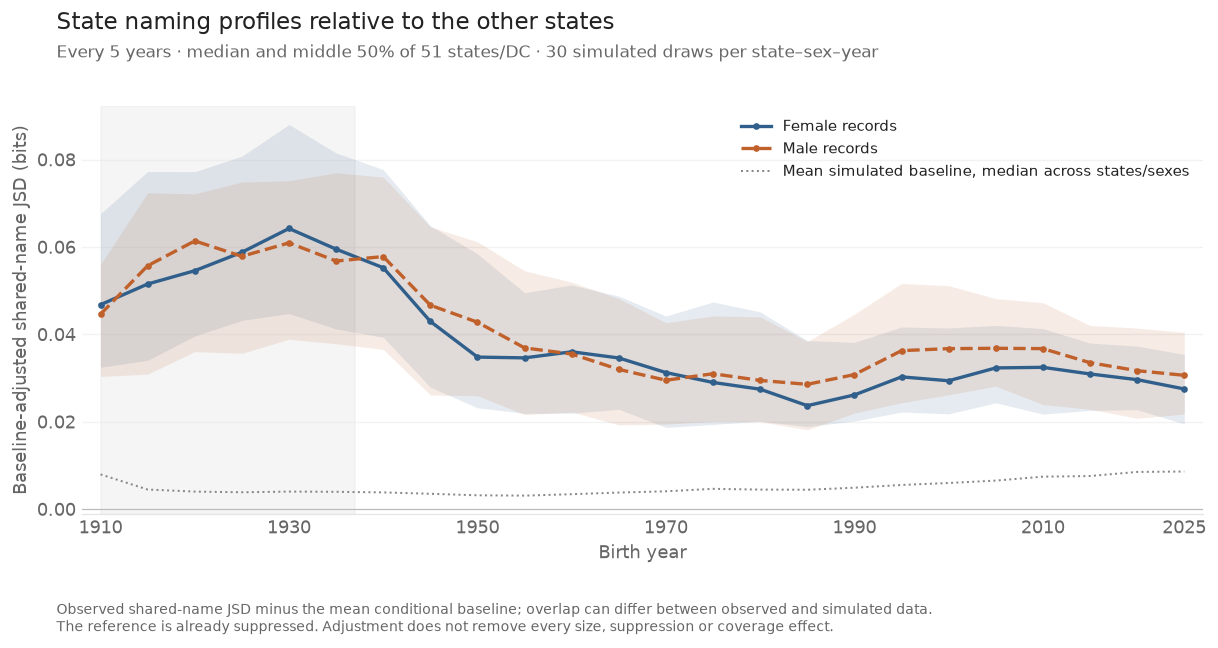

median_adjusted     q25     q75  median_observed  median_baseline
year sex                                                                   
1930 F             0.0642  0.0448  0.0880           0.0700           0.0041
     M             0.0609  0.0389  0.0752           0.0655           0.0038
1985 F             0.0237  0.0189  0.0386           0.0334           0.0054
     M             0.0286  0.0182  0.0384           0.0324           0.0036
2025 F             0.0275  0.0195  0.0354           0.0397           0.0093
     M             0.0306  0.0218  0.0404           0.0408           0.0075

In [5]:
# JSD is evaluated only on names with positive published counts in both distributions.
def jsd_shared(first, second):
    shared = (first > 0) & (second > 0)
    # Empty overlap does not define a probability distribution.
    if not shared.any():
        return np.nan
    p, q = first[shared].astype(float), second[shared].astype(float)
    p, q = p / p.sum(), q / q.sum()
    midpoint = (p + q) / 2
    return .5 * (np.sum(p * np.log2(p / midpoint)) + np.sum(q * np.log2(q / midpoint)))

DRAWS, SEED = 30, 2026
rng = np.random.default_rng(SEED)
rows = []
for (year, sex), group in st.loc[st['year'].mod(5).eq(0)].groupby(['year', 'sex'], observed=True):
    counts = group.pivot_table(index='name', columns='state', values='count',
                              aggfunc='sum', fill_value=0, observed=True)
    total = counts.sum(axis=1).to_numpy()
    for state in counts.columns:
        current = counts[state].to_numpy()
        rest = total - current
        observed = jsd_shared(current, rest)
        # Conditional benchmark: draw the state's published total from the published rest.
        # Simulated counts below 5 are hidden; this does not recover true unreported counts.
        samples = rng.multinomial(int(current.sum()), rest / rest.sum(), size=DRAWS)
        simulated = [jsd_shared(np.where(sample >= 5, sample, 0), rest) for sample in samples]
        valid = np.asarray(simulated)[np.isfinite(simulated)]
        baseline = float(valid.mean()) if len(valid) else np.nan
        baseline_sd = float(valid.std(ddof=1)) if len(valid) > 1 else np.nan
        rows.append({'year': int(year), 'sex': str(sex), 'state': str(state),
            'published_count': int(current.sum()), 'observed_jsd': float(observed),
            'baseline_mean': baseline, 'baseline_sd': baseline_sd,
            'baseline_mc_se': baseline_sd / np.sqrt(len(valid)) if len(valid) else np.nan,
            'adjusted_jsd': float(observed - baseline), 'draws': DRAWS,
            'valid_draws': len(valid)})
    if sex == 'M':
        print(f'Completed conditional baseline for {year}.')
dv = pd.DataFrame(rows)
dv.to_csv(TABLES / 'state_divergence.csv', index=False)
div_trend = dv.groupby(['year', 'sex']).agg(
    median_adjusted=('adjusted_jsd', 'median'),
    q25=('adjusted_jsd', lambda v: v.quantile(.25)),
    q75=('adjusted_jsd', lambda v: v.quantile(.75)),
    median_observed=('observed_jsd', 'median'), median_baseline=('baseline_mean', 'median'))
div_trend.reset_index().to_csv(TABLES / 'state_divergence_by_year.csv', index=False)
by_state = dv.loc[dv['year'].eq(2025)].groupby('state').agg(
    adjusted_jsd=('adjusted_jsd', 'mean'), published_count=('published_count', 'sum'))
both_median = dv.groupby('year')['adjusted_jsd'].median()
peak_year = int(both_median.loc[:1945].idxmax())
minimum_year = int(both_median.loc[1945:].idxmin())
size_2025 = gs.xs(2025, level='year')['published_count'].groupby('state', observed=True).sum()
conc_2025 = gs.xs(2025, level='year')['top10_share'].groupby('state', observed=True).mean()
NUM['divergence'] = {
    'draws_per_state_sex_year': DRAWS, 'seed': SEED, 'observations': len(dv),
    'summary_unit': 'median across 102 state-sex observations',
    'peak_before1945_year': peak_year, 'peak_before1945': float(both_median.loc[peak_year]),
    'minimum_after1945_year': minimum_year, 'minimum_after1945': float(both_median.loc[minimum_year]),
    'adjusted_2025': float(both_median.loc[2025]),
    'baseline_2025': float(dv.loc[dv['year'].eq(2025), 'baseline_mean'].median()),
    'size_rank_correlation_2025': float(by_state['adjusted_jsd'].rank().corr(by_state['published_count'].rank())),
    'concentration_size_rank_correlation_2025': float(conc_2025.rank().corr(size_2025.rank())),
    'highest_states_2025': by_state['adjusted_jsd'].nlargest(5).index.tolist(),
    'lowest_states_2025': by_state['adjusted_jsd'].nsmallest(3).index.tolist()
}
fig, ax = plt.subplots(figsize=(10.5, 5.4))
for sex, label in [('F', 'Female records'), ('M', 'Male records')]:
    v = div_trend.xs(sex, level='sex')
    ax.fill_between(v.index, v['q25'], v['q75'], color=COLORS[sex], alpha=.12, lw=0)
    ax.plot(v.index, v['median_adjusted'], color=COLORS[sex], lw=2,
            ls='-' if sex == 'F' else '--', marker='o', ms=3, label=label)
baseline_median = dv.groupby('year')['baseline_mean'].median()
ax.plot(baseline_median.index, baseline_median, color='#888888', lw=1.2, ls=':',
        label='Mean simulated baseline, median across states/sexes')
ax.axvspan(1910, 1937, color=GRID, alpha=.4, zorder=0)
ax.axhline(0, color='#bbbbbb', lw=.7)
ax.set(xlabel='Birth year', ylabel='Baseline-adjusted shared-name JSD (bits)', xlim=(1908, 2027))
ax.set_xticks([1910, 1930, 1950, 1970, 1990, 2010, 2025])
ax.grid(axis='y', lw=.8)
ax.legend(frameon=False, fontsize=9, loc='upper right')
header(fig, 'State naming profiles relative to the other states',
       'Every 5 years · median and middle 50% of 51 states/DC · 30 simulated draws per state–sex–year')
footer(fig, 'Observed shared-name JSD minus the mean conditional baseline; overlap can differ between observed and simulated data.' + chr(10) +
       'The reference is already suppressed. Adjustment does not remove every size, suppression or coverage effect.')
fig.subplots_adjust(left=.09, right=.98, top=.83, bottom=.20)
save(fig, 'fig4_state_divergence.png')
display(div_trend.loc[[1930, 1985, 2025]].round(4))

### RQ2: distinctive names

For 2016–2025, divide a name’s published share in each state by its share in the pooled other states within recorded sex. Exclude placeholder-like labels from both numerators and denominators, require at least 200 published counts in the focal state and a positive count elsewhere, then choose the largest ratio. This is relative over-representation, not absolute popularity or evidence of ethnicity, culture or causal influence.

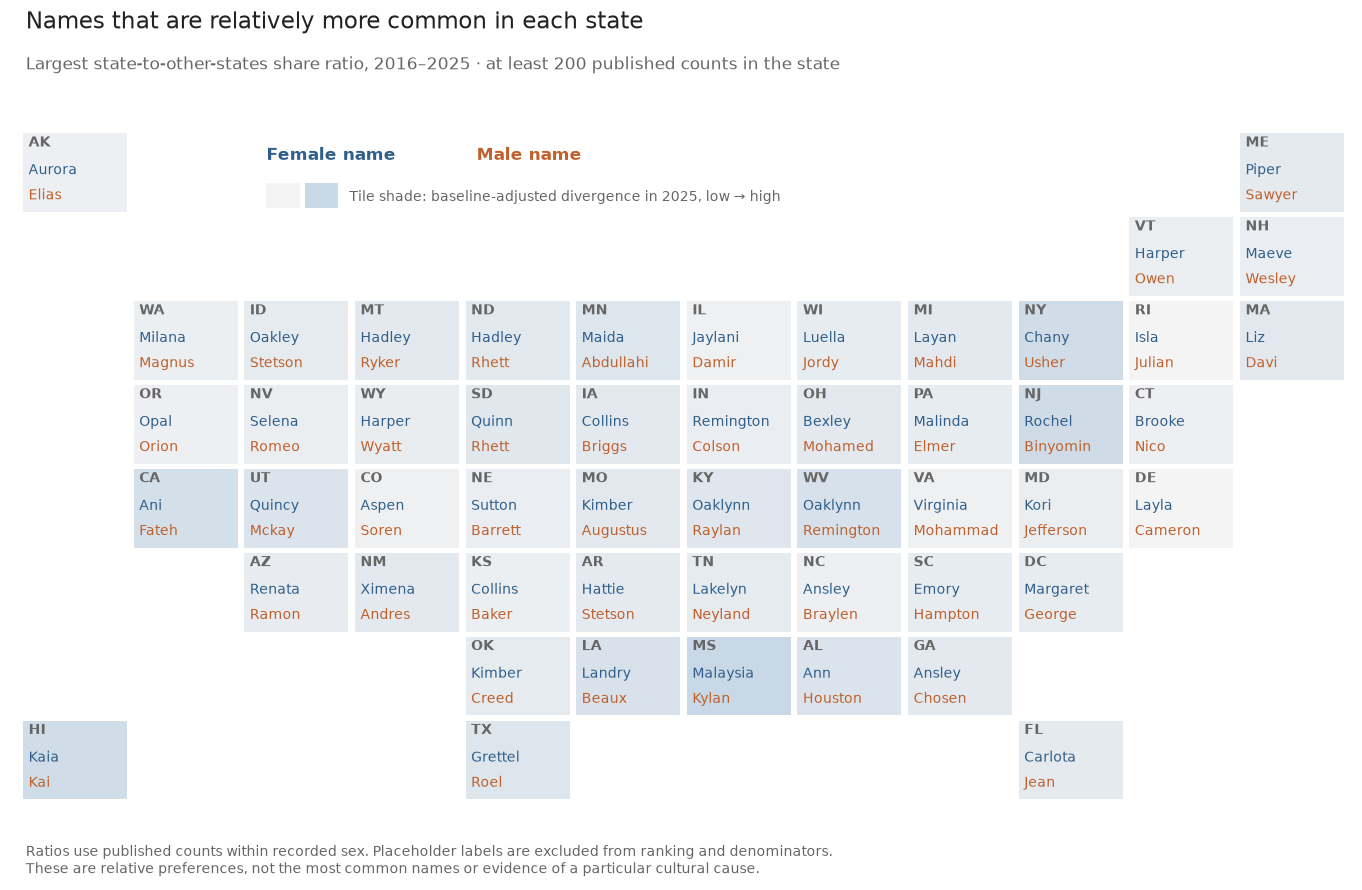

,state,sex,name,count,relative_share
43828,HI,F,Kaia,253,11.01
44390,HI,M,Kai,397,4.29
65003,LA,F,Landry,277,9.13
65825,LA,M,Beaux,272,19.84
81262,MN,F,Maida,236,348.62
81914,MN,M,Abdullahi,308,158.95
101967,NJ,F,Rochel,593,52.91
102732,NJ,M,Binyomin,255,84.89


In [6]:
# Compare each name's share with the pooled other states over the same ten years.
recent_state = st.loc[st['year'].between(2016, 2025)
                      & ~st['name'].str.lower().isin(PLACEHOLDERS)]
distinct = recent_state.groupby(['state', 'sex', 'name'], observed=True)['count'].sum().reset_index()
distinct = distinct.join(
    distinct.groupby(['sex', 'name'], observed=True)['count'].sum().rename('pooled_count'),
    on=['sex', 'name'])
distinct['other_count'] = distinct['pooled_count'] - distinct['count']
state_total = distinct.groupby(['state', 'sex'], observed=True)['count'].transform('sum')
pooled_total = distinct.groupby('sex', observed=True)['count'].transform('sum')
distinct['relative_share'] = ((distinct['count'] / state_total)
                              / (distinct['other_count'] / (pooled_total - state_total)))
eligible_distinct = distinct.loc[distinct['count'].ge(200) & distinct['other_count'].gt(0)]
best_names = eligible_distinct.loc[
    eligible_distinct.groupby(['state', 'sex'], observed=True)['relative_share'].idxmax()].copy()
best_names.to_csv(TABLES / 'distinctive_names_2016_2025.csv', index=False)
name_tiles = best_names.pivot(index='state', columns='sex', values='name')
NUM['distinctive_names'] = {'period': [2016, 2025], 'minimum_state_count': 200,
                            'median_relative_share': float(best_names['relative_share'].median())}

# A tile map keeps all 50 states and DC legible without adding a map dependency.
TILES = {'AK': (0, 0), 'ME': (0, 11), 'VT': (1, 10), 'NH': (1, 11),
         'WA': (2, 1), 'ID': (2, 2), 'MT': (2, 3), 'ND': (2, 4), 'MN': (2, 5),
         'IL': (2, 6), 'WI': (2, 7), 'MI': (2, 8), 'NY': (2, 9), 'RI': (2, 10), 'MA': (2, 11),
         'OR': (3, 1), 'NV': (3, 2), 'WY': (3, 3), 'SD': (3, 4), 'IA': (3, 5),
         'IN': (3, 6), 'OH': (3, 7), 'PA': (3, 8), 'NJ': (3, 9), 'CT': (3, 10),
         'CA': (4, 1), 'UT': (4, 2), 'CO': (4, 3), 'NE': (4, 4), 'MO': (4, 5),
         'KY': (4, 6), 'WV': (4, 7), 'VA': (4, 8), 'MD': (4, 9), 'DE': (4, 10),
         'AZ': (5, 2), 'NM': (5, 3), 'KS': (5, 4), 'AR': (5, 5), 'TN': (5, 6),
         'NC': (5, 7), 'SC': (5, 8), 'DC': (5, 9), 'OK': (6, 4), 'LA': (6, 5),
         'MS': (6, 6), 'AL': (6, 7), 'GA': (6, 8), 'HI': (7, 0), 'TX': (7, 4), 'FL': (7, 9)}
tile_cmap = LinearSegmentedColormap.from_list('state_tile', ['#f4f4f4', '#c9d8e6'])
tile_score = by_state['adjusted_jsd']
tile_shade = (tile_score - tile_score.min()) / (tile_score.max() - tile_score.min())
fig5, ax5 = plt.subplots(figsize=(11.5, 7.5))
for state, (row, col) in TILES.items():
    ax5.add_patch(plt.Rectangle((col, -row), .94, .94,
                               color=tile_cmap(float(tile_shade.loc[state])), lw=0))
    ax5.text(col + .05, -row + .78, state, fontsize=8.5, color=MUTED, weight='bold')
    ax5.text(col + .05, -row + .45, name_tiles.loc[state, 'F'], fontsize=8.4, color=COLORS['F'])
    ax5.text(col + .05, -row + .15, name_tiles.loc[state, 'M'], fontsize=8.4, color=COLORS['M'])
ax5.set(xlim=(-.1, 12), ylim=(-7.1, 1.05))
ax5.axis('off')
ax5.text(2.2, .62, 'Female name', color=COLORS['F'], fontsize=10, weight='bold')
ax5.text(4.1, .62, 'Male name', color=COLORS['M'], fontsize=10, weight='bold')
for position, shade in [(2.2, 0.0), (2.55, 1.0)]:
    ax5.add_patch(plt.Rectangle((position, .05), .3, .3, color=tile_cmap(shade), lw=0))
ax5.text(2.95, .13, 'Tile shade: baseline-adjusted divergence in 2025, low → high',
         fontsize=8.5, color=MUTED)
header(fig5, 'Names that are relatively more common in each state',
       'Largest state-to-other-states share ratio, 2016–2025 · at least 200 published counts in the state', x=.03)
footer(fig5, 'Ratios use published counts within recorded sex. Placeholder labels are excluded from ranking and denominators.'
       + chr(10) + 'These are relative preferences, not the most common names or evidence of a particular cultural cause.', x=.03)
fig5.subplots_adjust(left=.02, right=.99, top=.85, bottom=.09)
save(fig5, 'fig5_distinctive_map.png')
display(best_names.loc[best_names['state'].isin(['MN', 'NJ', 'HI', 'LA']),
                       ['state', 'sex', 'name', 'count', 'relative_share']].round(2))


## RQ3: stability of recorded-sex associations

Compare each name's first complete decade with at least **1,000 published counts**, occurring by the 1990s, with **2016–2025**, also requiring at least 1,000 counts. This is a cohort of historically common names that remain common, not all names. For every ten-year window, unpublished annual counts contribute **0–4 per sex** under the publication-threshold assumption, including years when neither sex is published.

Female share is bounded by `F_lower / (F_lower + M_upper)` and `F_upper / (F_upper + M_lower)`. A shift is classified only when the whole interval moves from below 30% to above 70%, or the reverse. The scatter shows interval midpoints. The second panel measures the share of national published counts associated with names whose annual female-share interval is wholly within 20–80% (definite), or intersects that range (possible). These bounds do not recover applications missing for reasons other than suppression.

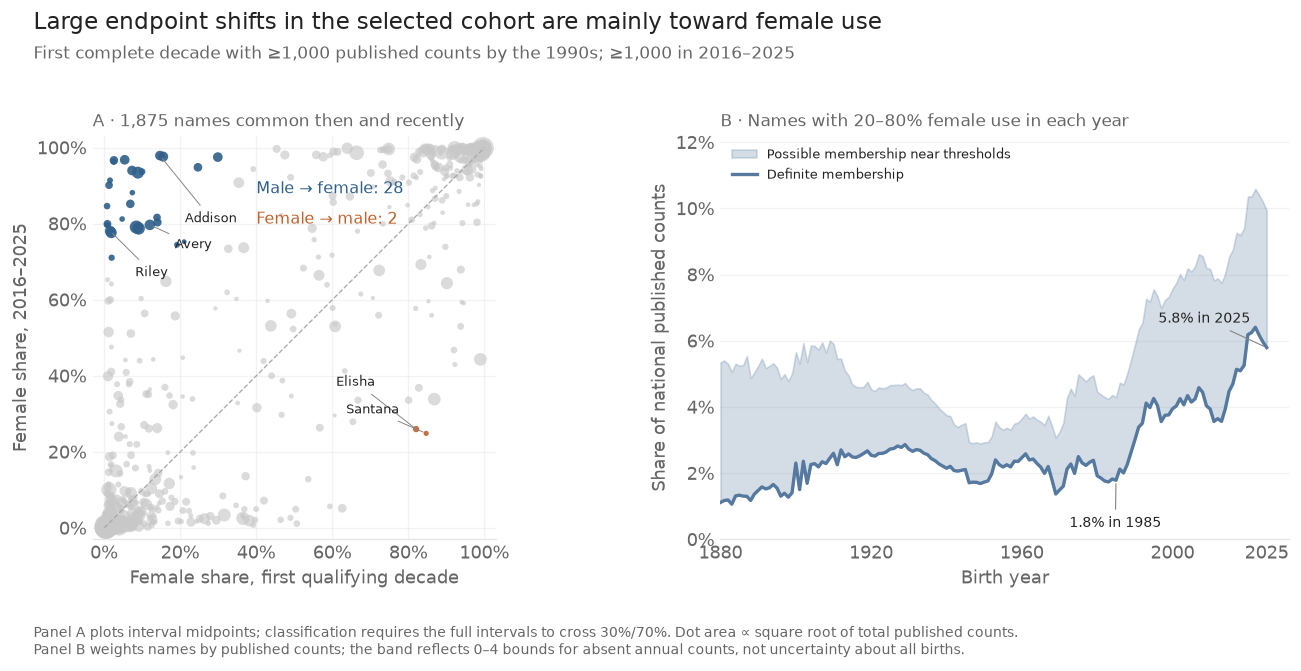

,Eligible names,M to F,F to M
0,1875,28,2


,definite_share,possible_share
year,,
1985,0.01786,0.04300
2022,0.06410,0.10595
2025,0.05796,0.09946


In [7]:
# Annual bounds use published counts as lower bounds, never observed zeros.
rq3_annual = nat.pivot_table(index=['name', 'year'], columns='sex', values='count',
                            observed=True).reindex(columns=['F', 'M'])
rq3_annual.columns.name = None
for rq3_sex in ['F', 'M']:
    rq3_annual[rq3_sex + '_lo'] = rq3_annual[rq3_sex].fillna(0)
    rq3_annual[rq3_sex + '_hi'] = rq3_annual[rq3_sex].fillna(4)
rq3_annual['published_count'] = rq3_annual['F_lo'] + rq3_annual['M_lo']
rq3_annual['female_lower'] = rq3_annual['F_lo'] / (rq3_annual['F_lo'] + rq3_annual['M_hi'])
rq3_annual['female_upper'] = rq3_annual['F_hi'] / (rq3_annual['F_hi'] + rq3_annual['M_lo'])

# All comparison windows contain ten years. An unpublished year contributes
# 0–4 to that sex, including years with neither sex published.
def rq3_period_bounds(frame, keys):
    totals = frame.groupby(keys + ['sex'], observed=True).agg(
        published_count=('count', 'sum'), published_years=('year', 'nunique'))
    low = totals['published_count'].unstack('sex').reindex(columns=['F', 'M']).fillna(0)
    years = totals['published_years'].unstack('sex').reindex(columns=['F', 'M']).fillna(0)
    high = low + 4 * (10 - years)
    result = pd.DataFrame({
        'published_count': low.sum(axis=1),
        'female_lower': low['F'] / (low['F'] + high['M']),
        'female_upper': high['F'] / (high['F'] + low['M']),
        'female_published': low['F'], 'male_published': low['M'],
        'female_upper_count': high['F'], 'male_upper_count': high['M']
    })
    return result

rq3_history = nat.loc[nat['year'].le(1999), ['name', 'sex', 'year', 'count']].copy()
rq3_history['decade'] = rq3_history['year'] // 10 * 10
rq3_decades = rq3_period_bounds(rq3_history, ['name', 'decade'])
rq3_first = (rq3_decades.loc[rq3_decades['published_count'].ge(1000)]
             .reset_index().sort_values(['name', 'decade'])
             .drop_duplicates('name').set_index('name'))
rq3_recent = rq3_period_bounds(nat.loc[nat['year'].between(2016, 2025)], ['name'])
rq3_recent = rq3_recent.loc[rq3_recent['published_count'].ge(1000)]
rq3_cohort = rq3_first[['decade', 'published_count', 'female_lower', 'female_upper']].rename(
    columns={'decade': 'first_decade', 'published_count': 'first_count',
             'female_lower': 'first_lower', 'female_upper': 'first_upper'}).join(
    rq3_recent[['published_count', 'female_lower', 'female_upper']].rename(
        columns={'published_count': 'recent_count', 'female_lower': 'recent_lower',
                 'female_upper': 'recent_upper'}), how='inner')
rq3_cohort['total_published_count'] = nat.groupby('name', observed=True)['count'].sum()
rq3_cohort['first_midpoint'] = (rq3_cohort['first_lower'] + rq3_cohort['first_upper']) / 2
rq3_cohort['recent_midpoint'] = (rq3_cohort['recent_lower'] + rq3_cohort['recent_upper']) / 2
rq3_cohort['shift'] = 'Other'
rq3_cohort.loc[(rq3_cohort['first_upper'] < .30) &
               (rq3_cohort['recent_lower'] > .70), 'shift'] = 'M to F'
rq3_cohort.loc[(rq3_cohort['first_lower'] > .70) &
               (rq3_cohort['recent_upper'] < .30), 'shift'] = 'F to M'
rq3_m2f = rq3_cohort.loc[rq3_cohort['shift'].eq('M to F')].sort_values(
    'total_published_count', ascending=False)
rq3_f2m = rq3_cohort.loc[rq3_cohort['shift'].eq('F to M')].sort_values(
    'total_published_count', ascending=False)

rq3_annual['definite_shared'] = (rq3_annual['female_lower'].ge(.20) &
                                rq3_annual['female_upper'].le(.80))
rq3_annual['possible_shared'] = (rq3_annual['female_upper'].ge(.20) &
                                rq3_annual['female_lower'].le(.80))
rq3_year_total = rq3_annual.groupby(level='year')['published_count'].sum()
rq3_shared = pd.DataFrame({
    'definite_share': rq3_annual['published_count'].where(
        rq3_annual['definite_shared'], 0).groupby(level='year').sum() / rq3_year_total,
    'possible_share': rq3_annual['published_count'].where(
        rq3_annual['possible_shared'], 0).groupby(level='year').sum() / rq3_year_total
})
rq3_cohort.to_csv(TABLES / 'name_sex_cohort.csv')
rq3_shared.to_csv(TABLES / 'shared_name_share_by_year.csv')
NUM['name_sex'] = {
    'cohort_names': len(rq3_cohort), 'male_to_female': len(rq3_m2f),
    'female_to_male': len(rq3_f2m),
    'male_to_female_names': rq3_m2f.index.tolist(),
    'female_to_male_names': rq3_f2m.index.tolist(),
    'shared_1985_lower': float(rq3_shared.loc[1985, 'definite_share']),
    'shared_1985_upper': float(rq3_shared.loc[1985, 'possible_share']),
    'shared_2025_lower': float(rq3_shared.loc[2025, 'definite_share']),
    'shared_2025_upper': float(rq3_shared.loc[2025, 'possible_share']),
    'shared_peak_year': int(rq3_shared['definite_share'].idxmax()),
    'shared_peak_lower': float(rq3_shared['definite_share'].max())
}

rq3_fig, (rq3_a, rq3_b) = plt.subplots(1, 2, figsize=(11.5, 5.6),
                                     gridspec_kw={'width_ratios': [1, 1.12]})
rq3_sizes = np.sqrt(rq3_cohort['total_published_count']) / 12
for rq3_label, rq3_color in [('Other', '#c8c8c8'), ('M to F', COLORS['F']), ('F to M', COLORS['M'])]:
    rq3_sub = rq3_cohort.loc[rq3_cohort['shift'].eq(rq3_label)]
    rq3_a.scatter(rq3_sub['first_midpoint'], rq3_sub['recent_midpoint'],
                  s=rq3_sizes.loc[rq3_sub.index], color=rq3_color,
                  alpha=.65 if rq3_label == 'Other' else .9, lw=0)
rq3_a.plot([0, 1], [0, 1], color='#aaa', lw=.8, ls='--')
rq3_a.text(.40, .88, f'Male → female: {len(rq3_m2f)}', color=COLORS['F'], fontsize=9.5)
rq3_a.text(.40, .80, f'Female → male: {len(rq3_f2m)}', color=COLORS['M'], fontsize=9.5)
rq3_labels = rq3_m2f.sort_values('recent_count', ascending=False).head(3).index.tolist() + rq3_f2m.index.tolist()
for rq3_i, rq3_name in enumerate(rq3_labels):
    rq3_row = rq3_cohort.loc[rq3_name]
    rq3_offset = (15, -14 - 13 * (rq3_i % 3)) if rq3_row['shift'] == 'M to F' else (-48, 12 + 14 * (rq3_i % 2))
    rq3_a.annotate(rq3_name, (rq3_row['first_midpoint'], rq3_row['recent_midpoint']),
                    xytext=rq3_offset, textcoords='offset points', fontsize=7.8,
                    arrowprops={'arrowstyle': '-', 'color': '#888', 'lw': .6})
rq3_a.set(xlabel='Female share, first qualifying decade', ylabel='Female share, 2016–2025',
           xlim=(-.03, 1.03), ylim=(-.03, 1.03))
pct(rq3_a)
pct(rq3_a, 'x')
rq3_a.set_aspect('equal')
rq3_a.grid(lw=.7)
rq3_a.set_title(f'A · {len(rq3_cohort):,} names common then and recently', fontsize=10, color=MUTED)

rq3_b.fill_between(rq3_shared.index, rq3_shared['definite_share'], rq3_shared['possible_share'],
                   color='#55799f', alpha=.25, label='Possible membership near thresholds')
rq3_b.plot(rq3_shared.index, rq3_shared['definite_share'], color='#55799f', lw=2,
           label='Definite membership')
rq3_b.set(xlabel='Birth year', ylabel='Share of national published counts',
           xlim=(1880, 2031), ylim=(0, float(rq3_shared['possible_share'].max()) * 1.15))
rq3_b.set_xticks([1880, 1920, 1960, 2000, 2025])
pct(rq3_b)
rq3_b.grid(axis='y', lw=.7)
for rq3_y, rq3_offset in [(1985, (-28, -28)), (2025, (-65, 15))]:
    rq3_value = rq3_shared.loc[rq3_y, 'definite_share']
    rq3_b.annotate(f'{rq3_value:.1%} in {rq3_y}', (rq3_y, rq3_value),
                    xytext=rq3_offset, textcoords='offset points', fontsize=8.5,
                    arrowprops={'arrowstyle': '-', 'color': '#888', 'lw': .7})
rq3_b.legend(frameon=False, loc='upper left', fontsize=7.5)
rq3_b.set_title('B · Names with 20–80% female use in each year', fontsize=10, color=MUTED)
header(rq3_fig, 'Large endpoint shifts in the selected cohort are mainly toward female use',
       'First complete decade with ≥1,000 published counts by the 1990s; ≥1,000 in 2016–2025')
footer(rq3_fig, 'Panel A plots interval midpoints; classification requires the full intervals to cross 30%/70%. Dot area ∝ square root of total published counts.'
       + chr(10) + 'Panel B weights names by published counts; the band reflects 0–4 bounds for absent annual counts, not uncertainty about all births.')
rq3_fig.subplots_adjust(left=.075, right=.98, top=.79, bottom=.19, wspace=.32)
save(rq3_fig, 'fig6_sex_switch.png')
display(pd.DataFrame({'Eligible names': [len(rq3_cohort)], 'M to F': [len(rq3_m2f)], 'F to M': [len(rq3_f2m)]}))
display(rq3_shared.loc[[1985, 2022, 2025]].round(5))


### Selected trajectories from the same cohort

Choose the six largest male-to-female shifts and the two largest female-to-male shifts from the Figure 6 cohort, ranked by **total published counts over 1880–2025**. Annual trajectories require at least **200 published counts**. Lines show female-share interval midpoints, with the lower–upper range shaded; excluded years remain gaps. Selection is based on the endpoint rule, so intermediate reversals and mixed-use periods remain visible.

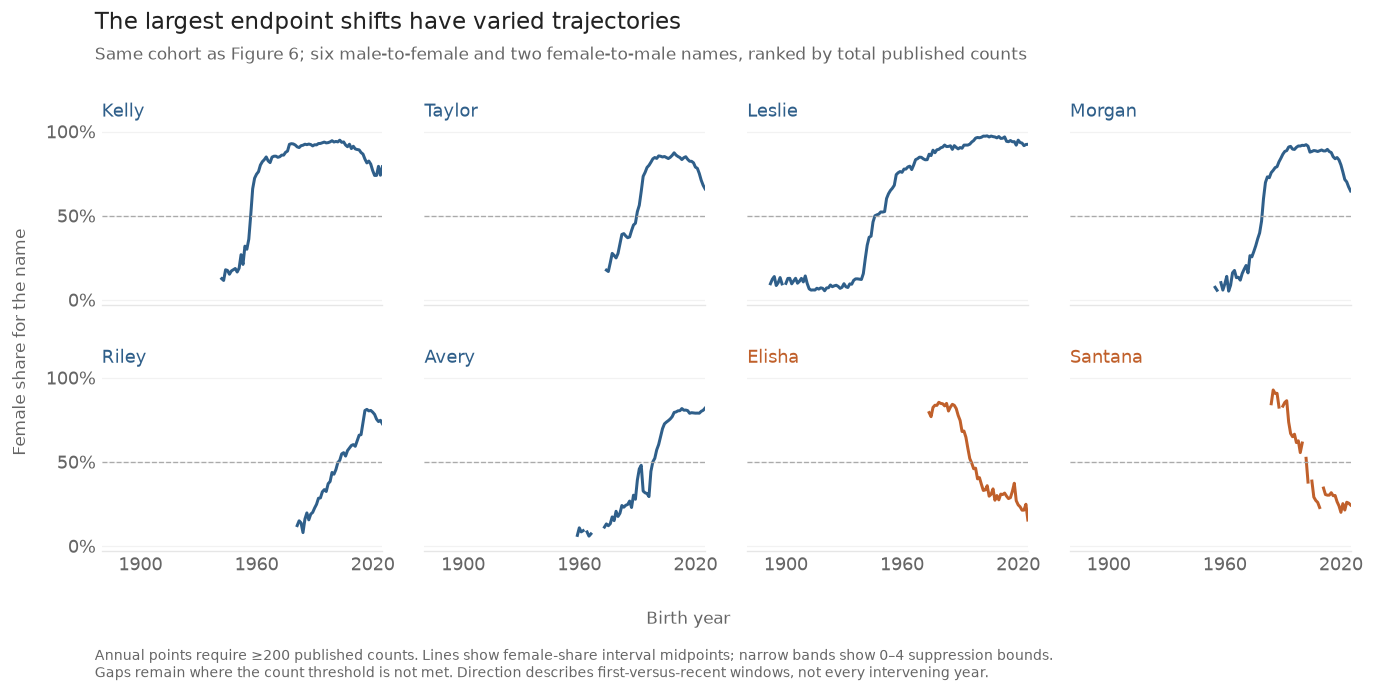

,shift,first_decade,first_lower,first_upper,recent_lower,recent_upper,total_published_count
name,,,,,,,
Kelly,M to F,1920,0.0846,0.0846,0.7910,0.7910,556365
Taylor,M to F,1960,0.0891,0.0925,0.7874,0.7874,443686
Leslie,M to F,1880,0.0889,0.0889,0.9341,0.9341,383418
Morgan,M to F,1910,0.0042,0.0335,0.7762,0.7762,269269
Riley,M to F,1910,0.0000,0.0320,0.7803,0.7803,246985
Avery,M to F,1920,0.1202,0.1202,0.7968,0.7968,236886
Elisha,F to M,1970,0.8202,0.8202,0.2599,0.2599,30034
Santana,F to M,1980,0.8466,0.8466,0.2487,0.2487,13726


1,723 of 1,875 names (91.9%) remain predominantly in the same category at both endpoints.


In [8]:
# Select from exactly the same endpoint cohort as Figure 6.
rq3_chosen = rq3_m2f.head(6).index.tolist() + rq3_f2m.head(2).index.tolist()
rq3_selected = rq3_cohort.loc[rq3_chosen].copy()
rq3_selected.to_csv(TABLES / 'name_sex_selected_names.csv')
rq3_traces = []
rq3_fig7, rq3_axes7 = plt.subplots(2, 4, figsize=(11.5, 5.8), sharex=True, sharey=True)
for rq3_name, rq3_ax in zip(rq3_chosen, rq3_axes7.flat):
    rq3_trace = rq3_annual.xs(rq3_name, level='name').reindex(range(1880, 2026)).copy()
    rq3_eligible = rq3_trace['published_count'].ge(200)
    rq3_low = rq3_trace['female_lower'].where(rq3_eligible)
    rq3_high = rq3_trace['female_upper'].where(rq3_eligible)
    rq3_mid = (rq3_low + rq3_high) / 2
    rq3_color = COLORS['F'] if rq3_name in rq3_m2f.index else COLORS['M']
    rq3_ax.fill_between(rq3_trace.index, rq3_low, rq3_high, color=rq3_color, alpha=.25, lw=0)
    rq3_ax.plot(rq3_trace.index, rq3_mid, color=rq3_color, lw=1.8)
    rq3_ax.axhline(.5, color='#aaa', lw=.8, ls='--')
    rq3_ax.set_title(rq3_name, fontsize=11, color=rq3_color)
    rq3_ax.set(xlim=(1880, 2025), ylim=(-.03, 1.03))
    rq3_ax.set_xticks([1900, 1960, 2020])
    rq3_ax.set_yticks([0, .5, 1])
    pct(rq3_ax)
    rq3_ax.grid(axis='y', lw=.7)
    rq3_export = rq3_trace[['published_count', 'female_lower', 'female_upper']].copy()
    rq3_export['name'] = rq3_name
    rq3_export['shown'] = rq3_eligible
    rq3_traces.append(rq3_export.reset_index(names='year'))
pd.concat(rq3_traces, ignore_index=True).to_csv(TABLES / 'name_sex_selected_trajectories.csv', index=False)
rq3_same_category = (((rq3_cohort['first_upper'] < .30) & (rq3_cohort['recent_upper'] < .30)) |
                     ((rq3_cohort['first_lower'] > .70) & (rq3_cohort['recent_lower'] > .70)))
NUM['name_sex'].update({
    'same_predominant_category': int(rq3_same_category.sum()),
    'same_predominant_fraction': float(rq3_same_category.mean()),
    'trajectory_names': rq3_chosen
})
rq3_fig7.supylabel('Female share for the name', x=.01, fontsize=10, color=MUTED)
rq3_fig7.supxlabel('Birth year', y=.09, fontsize=10, color=MUTED)
header(rq3_fig7, 'The largest endpoint shifts have varied trajectories',
       'Same cohort as Figure 6; six male-to-female and two female-to-male names, ranked by total published counts')
footer(rq3_fig7, 'Annual points require ≥200 published counts. Lines show female-share interval midpoints; narrow bands show 0–4 suppression bounds.'
       + chr(10) + 'Gaps remain where the count threshold is not met. Direction describes first-versus-recent windows, not every intervening year.')
rq3_fig7.subplots_adjust(left=.075, right=.98, top=.81, bottom=.20, hspace=.38, wspace=.15)
save(rq3_fig7, 'fig7_switchers.png')
display(rq3_selected[['shift', 'first_decade', 'first_lower', 'first_upper',
                       'recent_lower', 'recent_upper', 'total_published_count']].round(4))
print(f'{rq3_same_category.sum():,} of {len(rq3_cohort):,} names ({rq3_same_category.mean():.1%}) '
      'remain predominantly in the same category at both endpoints.')


## Save the numerical summaries

The figures and supporting tables are saved alongside the analysis. The numerical summary records the values used in the report.

In [9]:
# Summary table used in the report: pooled state counts and equally weighted state medians.
summary_stats = st.loc[st['year'].isin([1950, 1980, 2025])].groupby(
    ['year', 'sex'], observed=True).agg(
    published_count=('count', 'sum'), distinct_names=('name', 'nunique'))
summary_stats = summary_stats.join(trend['median'].rename('median_top10_share'))
summary_stats.reset_index().to_csv(TABLES / 'eda_summary.csv', index=False)

# Record the descriptive concentration timings and the post-1937 comparison.
gap_under_one_point = med['F'].sub(med['M']).abs().lt(.01)
NUM['concentration_timings'] = {
    'female_local_low_1950_1970': int(med.loc[1950:1970, 'F'].idxmin()),
    'gap_under_one_point_since': int(gap_under_one_point.iloc[::-1].cumprod().iloc[::-1]
                                   .loc[lambda values: values.eq(1)].index.min())
}
NUM['divergence']['adjusted_1940'] = float(both_median.loc[1940])
NUM['divergence']['decline_1940_1985'] = float(1 - both_median.loc[1985] / both_median.loc[1940])
(TABLES / 'eda_numbers.json').write_text(json.dumps(NUM, indent=2), encoding='utf-8')
display(summary_stats.round(4))
print('Saved seven figures and their supporting tables in reports/.')


published_count  distinct_names  median_top10_share
year sex                                                     
1950 F            1610017            2112              0.2798
     M            1720112            1721              0.3631
1980 F            1462212            3685              0.2219
     M            1668069            2502              0.2723
2025 F            1303470            5349              0.0962
     M            1466284            4368              0.1054

Saved seven figures and their supporting tables in reports/.
